# Regression Residual Diagnostics

**Family:** Multivariate & ML &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Multivariate & ML:* Explore many variables at once and explain or diagnose statistical and machine-learning models.

## Design purpose

A 2×2 panel of standard checks for a linear regression: residuals vs fitted (non-linearity), normal Q-Q (normality), scale-location (constant variance) and residuals vs leverage (influential points). It shows whether the model's assumptions hold before you trust its coefficients and p-values.

## When to use

- Validate any linear or generalized linear model before reporting it
- Find influential observations that drive the fit
- Decide whether to transform the outcome or add non-linear terms

## Avoid when

- The audience only needs the model's conclusions (keep this in the appendix)
- The model is not regression-based (use calibration or residual plots specific to that model)

## Alternatives

- Calibration plot (classification)
- Partial residual plots per predictor

## Design tips

- Add a smoothed trend line (LOWESS); a flat line at zero is what you want
- Label the few most extreme points by their row ID so they can be inspected
- Mark Cook's distance contours on the leverage panel

## Example

An ordinary-least-squares model of one-year disease progression on all 10 baseline variables of the real Diabetes dataset bundled with scikit-learn (load_diabetes, 442 patients), fitted with statsmodels.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import statsmodels.api as sm
from scipy import stats
from sklearn.datasets import load_diabetes
from statsmodels.nonparametric.smoothers_lowess import lowess

### Data

In [2]:
diab = load_diabetes(as_frame=True)
X = sm.add_constant(diab.data)
fit = sm.OLS(diab.target, X).fit()
infl = fit.get_influence()
d = pd.DataFrame({
    "fitted": fit.fittedvalues, "resid": fit.resid,
    "std_resid": infl.resid_studentized_internal,
    "leverage": infl.hat_matrix_diag, "cooks": infl.cooks_distance[0],
})
print(f"R² = {fit.rsquared:.2f}, n = {int(fit.nobs)}, p = {int(fit.df_model)}")
d.sort_values("cooks", ascending=False).head().round(3)

R² = 0.52, n = 442, p = 10


,fitted,resid,std_resid,leverage,cooks
382,246.294,-114.294,-2.170,0.054,0.024
123,174.788,-90.788,-1.740,0.072,0.021
169,220.203,-68.203,-1.333,0.108,0.020
304,122.059,130.941,2.459,0.033,0.019
92,192.599,-144.599,-2.706,0.027,0.018


### Plot

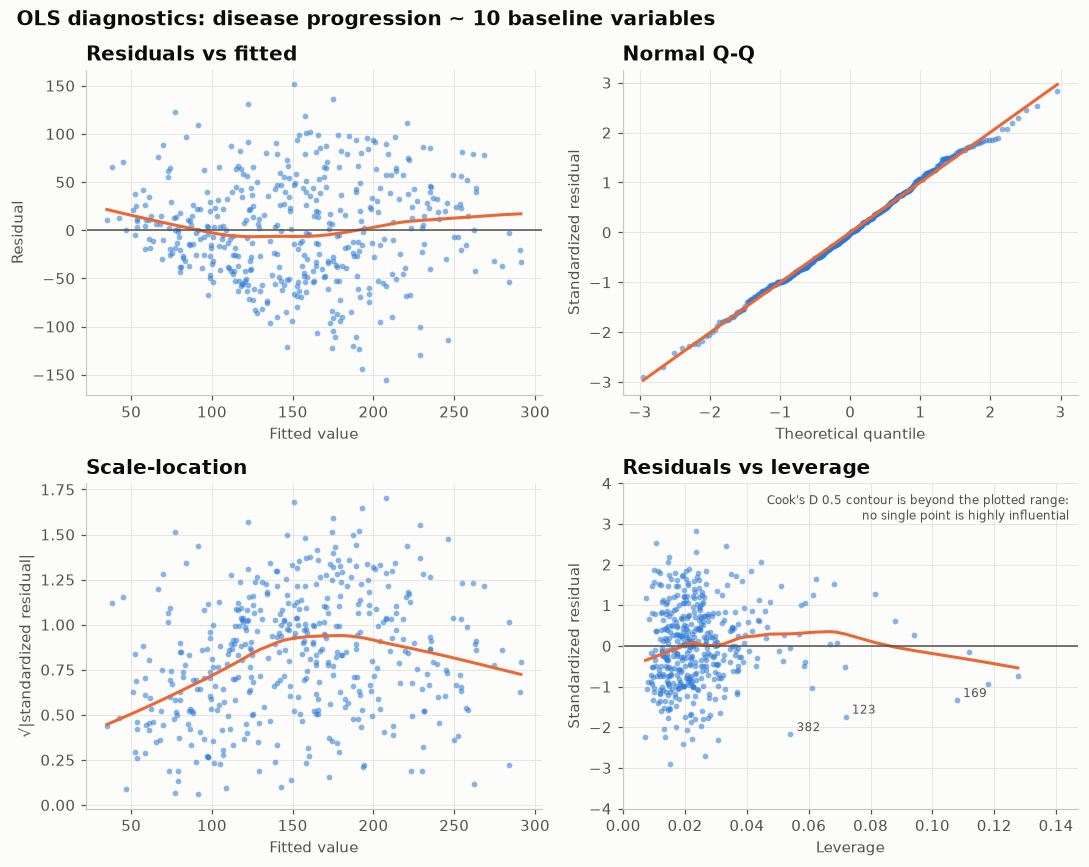

In [3]:
def trend(ax, x, y):
    sm_ = lowess(y, x, frac=0.6)
    ax.plot(sm_[:, 0], sm_[:, 1], color=PALETTE[1], lw=2)

pt = dict(s=14, alpha=0.55, color=PALETTE[0], linewidth=0)
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
ax = axes[0, 0]
ax.scatter(d["fitted"], d["resid"], **pt); trend(ax, d["fitted"], d["resid"])
ax.axhline(0, color="#52514e", lw=1)
ax.set(title="Residuals vs fitted", xlabel="Fitted value", ylabel="Residual")
ax = axes[0, 1]
(osm, osr), (slope, icpt, _) = stats.probplot(d["std_resid"], dist="norm")
ax.scatter(osm, osr, **pt)
ax.plot(osm, slope * osm + icpt, color=PALETTE[1], lw=2)
ax.set(title="Normal Q-Q", xlabel="Theoretical quantile", ylabel="Standardized residual")
ax = axes[1, 0]
sl = np.sqrt(np.abs(d["std_resid"]))
ax.scatter(d["fitted"], sl, **pt); trend(ax, d["fitted"], sl)
ax.set(title="Scale-location", xlabel="Fitted value", ylabel="√|standardized residual|")
ax = axes[1, 1]
ax.scatter(d["leverage"], d["std_resid"], **pt); trend(ax, d["leverage"], d["std_resid"])
ax.axhline(0, color="#52514e", lw=1)
p = int(fit.df_model) + 1
hx = np.linspace(d["leverage"].min() * 0.9, d["leverage"].max() * 1.1, 100)
hy = np.sqrt(0.5 * p * (1 - hx) / hx)          # Cook's distance = 0.5 contour
ax.plot(hx, hy, color="#b8b7b1", lw=1)
ax.plot(hx, -hy, color="#b8b7b1", lw=1)
ax.set_ylim(-4, 4)
note = ("Cook's D 0.5 contour is beyond the plotted range:\nno single point is highly influential"
        if hy.min() > 4 else "gray curves: Cook's D = 0.5")
ax.text(0.98, 0.97, note, transform=ax.transAxes, ha="right", va="top", fontsize=8, color="#52514e")
for i in d["cooks"].nlargest(3).index:
    ax.annotate(str(i), (d.at[i, "leverage"], d.at[i, "std_resid"]), xytext=(4, 2),
                textcoords="offset points", fontsize=8, color="#52514e")
ax.set(title="Residuals vs leverage", xlabel="Leverage", ylabel="Standardized residual")
fig.suptitle("OLS diagnostics: disease progression ~ 10 baseline variables",
             x=0.02, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

## How to read it

Top left, the residuals scatter evenly around zero with no curve, so a linear model is reasonable. Top right, the points follow the Q-Q line except slightly in the tails. Bottom left, the trend climbs at low fitted values and then levels off, a mild sign that errors are smaller for patients predicted to progress least (consider a transformed outcome). Bottom right, the Cook's distance 0.5 contour lies beyond the plotted range, so no single patient dominates the fit. The three most influential patients are labelled by row number for inspection.

---
Standalone script: [`residual_diagnostics.py`](residual_diagnostics.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)